<h1 style='color: green; font-size: 36px; font-weight: bold;'> Global Solution

Guilherme Macário da Silva - RM: 84057

Julio Cesar de Andrade Santana – RM 88100

Kaique Carvalho da Silva - RM: 93040

</h1>



**Análise de Micropartículas Plásticas com Regressão Linear**

`A Iniciativa Global de Microplásticos da Adventure Scientists reuniu um dos maiores e mais diversos conjuntos de dados globais sobre poluição por microplásticos até o momento. Esses dados estão sendo usados por empresas, governos e indivíduos para reduzir o desperdício de plástico. Cada círculo no mapa abaixo representa uma amostra de água coletada por voluntários. Clique nas setas duplas no canto superior esquerdo para ver a legenda do mapa. Ao clicar em um círculo, você pode ver a concentração de microplásticos encontrada naquela amostra de água. Círculos maiores representam mais microplásticos por litro. Esses dados já inspiraram empresas a reduzir seu consumo de plástico, estão sendo usados por governos para tomada de decisões de conservação e motivaram mais de 80% dos nossos voluntários a agir na redução da poluição por plástico.`

Fonte:https://www.ncei.noaa.gov/access/metadata/landing-page/bin/iso?id=gov.noaa.nodc:0211009

##Bibliotecas que iremos utilizar.

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression

from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

#para visualizar dados
import altair as alt

In [ ]:
dados = pd.read_csv('/content/Microplastic_Data_AdventureScientists.csv')

## Verificando o tamanho do dataset

In [ ]:
dados.shape

(1393, 4)

In [ ]:
dados.info

<bound method DataFrame.info of      Sample Date   Latitude   Longitude  Total Pieces/L 
0     2013-07-01  59.378683 -153.520867                1
1     2013-07-01  59.368133 -153.552333                1
2     2013-07-01  59.341467 -153.549767               14
3     2013-07-01  59.638717 -153.395667               17
4     2013-07-01  59.373600 -153.448067               71
...          ...        ...         ...              ...
1388  2017-03-30 -51.934450  -58.012670                0
1389         NaT  63.221610  -41.405960                3
1390         NaT  63.470810  -41.934710                0
1391         NaT  65.610920  -37.645740                1
1392         NaT   9.958530  -84.891080                9

[1393 rows x 4 columns]>

In [ ]:

dados.head()

,Sample Date,Latitude,Longitude,Total Pieces/L
0,2013-07-01,59.378683,-153.520867,1
1,2013-07-01,59.368133,-153.552333,1
2,2013-07-01,59.341467,-153.549767,14
3,2013-07-01,59.638717,-153.395667,17
4,2013-07-01,59.373600,-153.448067,71


In [ ]:
# Remover as colunas 'Unnamed: 4', 'Unnamed: 5' e 'Unnamed: 6'
dados = dados.drop(columns=['Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6'])

##Visualizando os dados

In [ ]:
dados.head()

,Sample Date,Latitude,Longitude,Total Pieces/L
0,2013-07-01,59.378683,-153.520867,1
1,2013-07-01,59.368133,-153.552333,1
2,2013-07-01,59.341467,-153.549767,14
3,2013-07-01,59.638717,-153.395667,17
4,2013-07-01,59.373600,-153.448067,71


In [ ]:
#convertendo a coluna para data.
dados['Sample Date'] = pd.to_datetime(dados['Sample Date'])

In [ ]:
#colocando as datas em ordem crescente.
dados = dados.sort_values(by='Sample Date')

In [ ]:
dados.head()

,Sample Date,Latitude,Longitude,Total Pieces/L
0,2013-07-01,59.378683,-153.520867,1
1,2013-07-01,59.368133,-153.552333,1
2,2013-07-01,59.341467,-153.549767,14
3,2013-07-01,59.638717,-153.395667,17
4,2013-07-01,59.373600,-153.448067,71


# <font color='red' style='font-size: 30px;'>Análises Preliminares</font>
<hr style='border: 2px solid red;'>


## Estatísticas descritivas

In [ ]:
dados.describe()

,Sample Date,Latitude,Longitude,Total Pieces/L,Unnamed: 4,Unnamed: 5,Unnamed: 6
count,1389,1393.000000,1393.000000,1393.000000,0.0,0.0,0.0
mean,2015-04-17 06:05:57.667386624,17.360050,-50.711904,12.750179,NaN,NaN,NaN
min,2013-07-01 00:00:00,-65.177500,-169.926130,0.000000,NaN,NaN,NaN
25%,2014-11-25 00:00:00,14.302333,-83.154150,1.000000,NaN,NaN,NaN
50%,2014-12-09 00:00:00,18.704733,-56.433333,4.000000,NaN,NaN,NaN
75%,2015-09-15 00:00:00,29.467000,-28.020000,12.000000,NaN,NaN,NaN
max,2017-03-30 00:00:00,81.090000,174.135000,323.000000,NaN,NaN,NaN
std,NaN,26.967994,66.246497,27.319984,NaN,NaN,NaN


## Matriz de correlação

In [ ]:
dados.corr().round(4)

,Sample Date,Latitude,Longitude,Total Pieces/L,Unnamed: 4,Unnamed: 5,Unnamed: 6
Sample Date,1.0000,-0.0741,0.0033,0.0137,NaN,NaN,NaN
Latitude,-0.0741,1.0000,-0.2893,0.1157,NaN,NaN,NaN
Longitude,0.0033,-0.2893,1.0000,-0.0224,NaN,NaN,NaN
Total Pieces/L,0.0137,0.1157,-0.0224,1.0000,NaN,NaN,NaN
Unnamed: 4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Unnamed: 5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Unnamed: 6,NaN,NaN,NaN,NaN,NaN,NaN,NaN


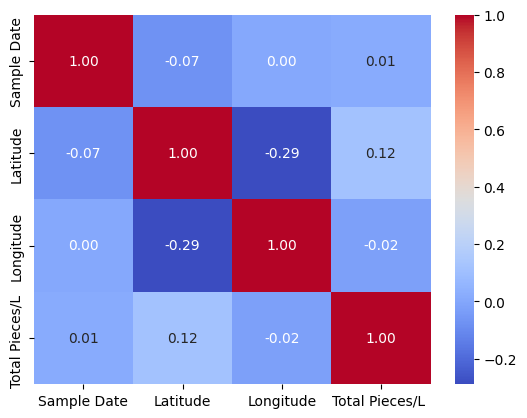

In [ ]:
matriz_correlacao = dados.corr().round(4)
matriz_correlacao

# Gerando um heatmap com seaborn
sns.heatmap(matriz_correlacao, annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

# <font color='red' style='font-size: 30px;'>Comportamento da Variável Dependente (Y) - Target</font


<hr style='border: 2px solid red;'>

# Análises gráficas

## Plotando a variável *dependente* (y)


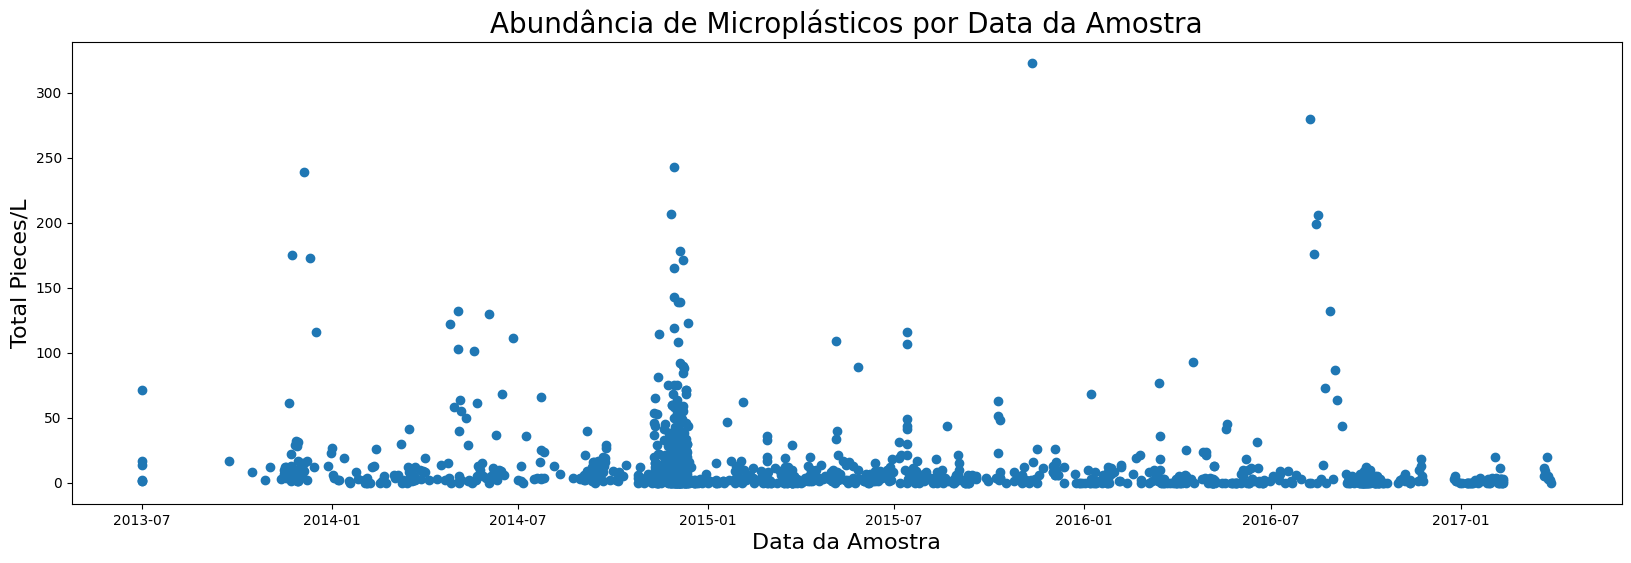

In [ ]:


# Crie um gráfico de dispersão com `Sample Date` no eixo x e `Total Pieces/L ` no eixo y.
plt.figure(figsize=(20, 6))
plt.scatter(dados['Sample Date'], dados['Total Pieces/L '])

# Defina o título do gráfico como 'Abundância de Microplásticos por Data da Amostra'.
plt.title('Abundância de Microplásticos por Data da Amostra', fontsize=20)

# Defina o rótulo do eixo y como 'Total Pieces/L' e o rótulo do eixo x como 'Data da Amostra'.
plt.ylabel('Total Pieces/L', fontsize=16)
plt.xlabel('Data da Amostra', fontsize=16)

# Exiba o gráfico.
plt.show()


# <font color='red' style='font-size: 30px;'>Distribuição de Frequências</font>
<hr style='border: 2px solid red;'>

## Distribuição de frequências da variável *dependente* (y)




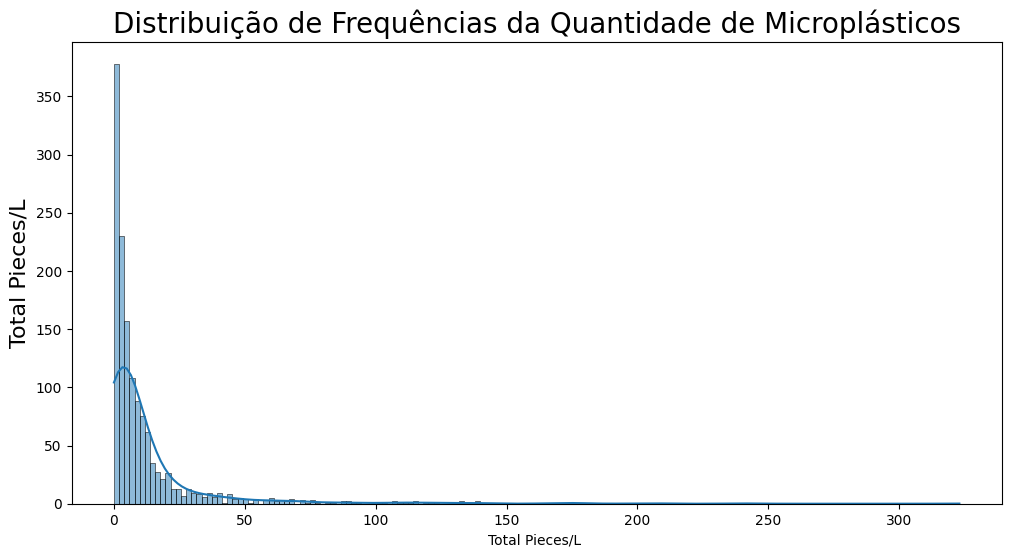

In [ ]:

# Criar um histograma da coluna `Total Pieces/L `
plt.figure(figsize=(12, 6))
sns.histplot(dados['Total Pieces/L '], kde=True)

# Definir o título do gráfico
plt.title('Distribuição de Frequências da Quantidade de Microplásticos', fontsize=20)

# Definir o rótulo do eixo y
plt.ylabel('Total Pieces/L', fontsize=16)

# Exibir o gráfico
plt.show()



# <font color='red' style='font-size: 30px;'>Variável Dependente X Variáveis Explicativas (pairplot)</font>
<hr style='border: 2px solid red;'>

## Gráficos de dispersão entre as variáveis do dataset

## seaborn.pairplot

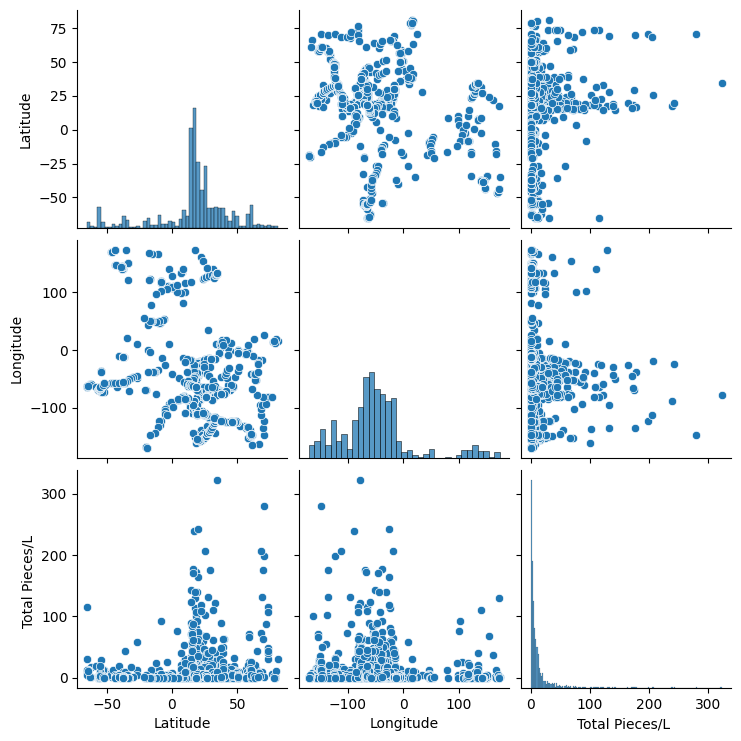

In [ ]:
ax = sns.pairplot(dados)

## Plotando o pairplot fixando somente uma variável no eixo y

In [ ]:
# Remover as colunas 'Unnamed: 4', 'Unnamed: 5' e 'Unnamed: 6'
# dados = dados.drop(columns=['Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6'])

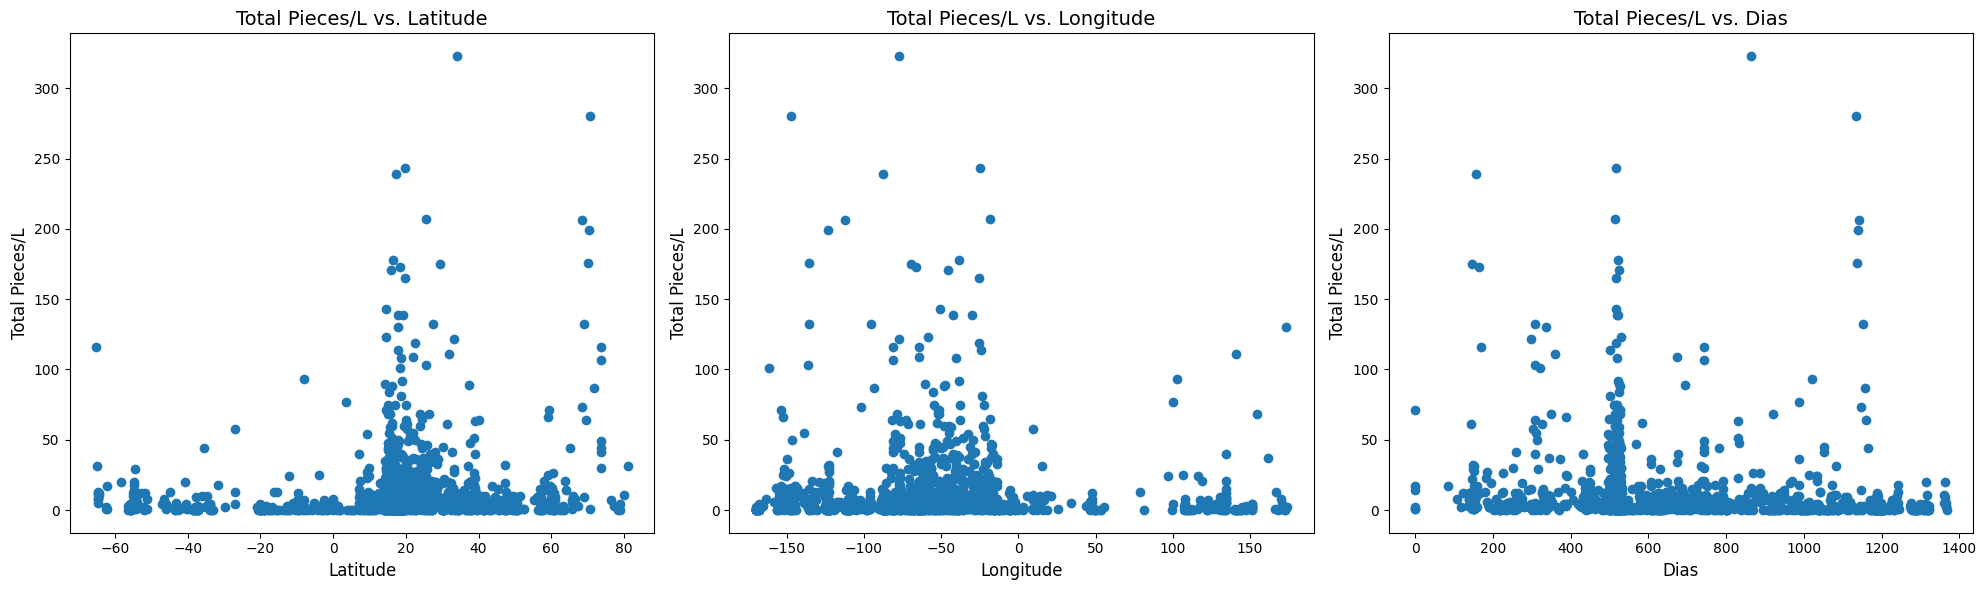

In [ ]:
# 1. Calcular a diferença em dias entre cada data e a primeira data
first_date = dados['Sample Date'].min()
dados['Dias'] = (dados['Sample Date'] - first_date).dt.days

# 2. Criar um novo DataFrame com as colunas numéricas
dados_numericos = dados[['Total Pieces/L ', 'Latitude', 'Longitude', 'Dias']]

# 3. Plotar gráficos de dispersão com `Total Pieces/L` no eixo y e as variáveis `Latitude`, `Longitude` e `Dias` no eixo x
fig, axs = plt.subplots(1, 3, figsize=(20, 6))

for i, col in enumerate(['Latitude', 'Longitude', 'Dias']):
    axs[i].scatter(dados_numericos[col], dados_numericos['Total Pieces/L '])
    axs[i].set_title(f'Total Pieces/L vs. {col}', fontsize=14)
    axs[i].set_xlabel(col, fontsize=12)
    axs[i].set_ylabel('Total Pieces/L', fontsize=12)

# 4. Ajustar o layout para evitar sobreposição dos títulos
plt.tight_layout()

# 5. Exibir o gráfico
plt.show()

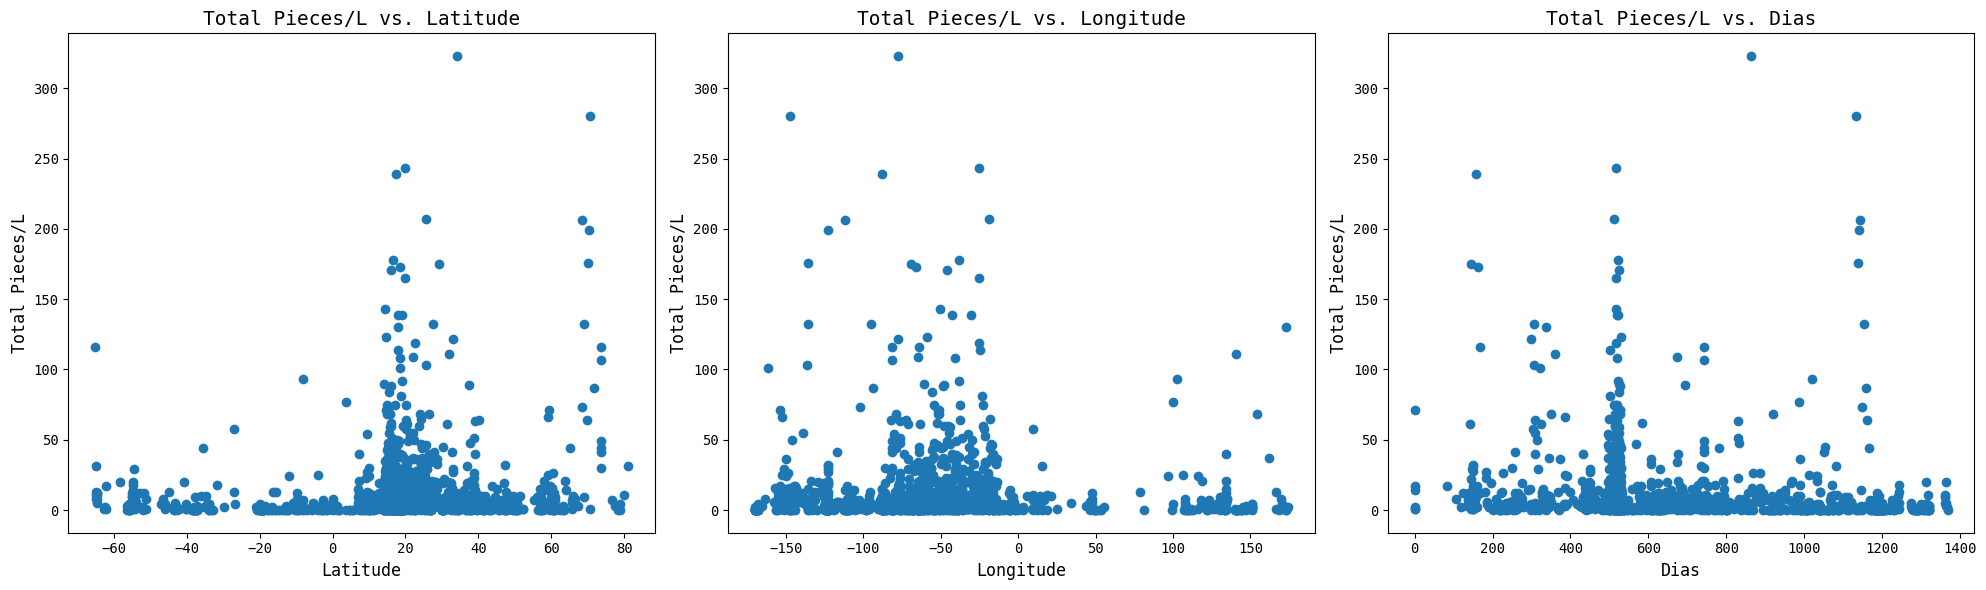

In [ ]:


# 1. Calcular a diferença em dias entre cada data e a primeira data
first_date = dados['Sample Date'].min()
dados['Dias'] = (dados['Sample Date'] - first_date).dt.days

# 2. Criar um novo DataFrame com as colunas numéricas
dados_numericos = dados[['Total Pieces/L ', 'Latitude', 'Longitude', 'Dias']]

# 3. Plotar gráficos de dispersão com 'Total Pieces/L' no eixo y e as variáveis 'Latitude', 'Longitude' e 'Dias' no eixo x
fig, axs = plt.subplots(1, 3, figsize=(20, 6))

# Definir a fonte para todos os elementos do gráfico
plt.rcParams['font.family'] = 'monospace'  # ou a fonte desejada

for i, col in enumerate(['Latitude', 'Longitude', 'Dias']):
    axs[i].scatter(dados_numericos[col], dados_numericos['Total Pieces/L '])
    axs[i].set_title(f'Total Pieces/L vs. {col}', fontsize=14)
    axs[i].set_xlabel(col, fontsize=12)
    axs[i].set_ylabel('Total Pieces/L', fontsize=12)

# 4. Ajustar o layout para evitar sobreposição dos títulos
plt.tight_layout()

# 5. Exibir o gráfico
plt.show()


 <font color='red' style='font-size: 30px;'>Estimando um Modelo de Regressão Linear </font>
<hr style='border: 2px solid red;'>

# Regressão Linear
<hr>

<p style='font-size: 20px; line-height: 2; margin: 10px 50px; text-align: justify;'>A análise de regressão diz respeito ao estudo da dependência de uma variável (a variável <b>dependente</b>) em relação a uma ou mais variáveis, as variáveis explanatórias, visando estimar e/ou prever o valor médio da primeira em termos dos valores conhecidos ou fixados das segundas.</p>

Preparar os Dados

In [ ]:
first_date = dados['Sample Date'].min()
dados['Dias'] = (dados['Sample Date'] - first_date).dt.days

Separar Variáveis Dependentes e Independentes

In [ ]:
# 2.1. Variável dependente (y)
y = dados['Total Pieces/L ']

# 2.2. Variáveis independentes (X)
X = dados[['Latitude', 'Longitude', 'Dias']]


Criar Conjuntos de Treino e Teste

In [ ]:
# 3.1. Dividir os dados em treino (70%) e teste (30%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)


Instanciar e Treinar o Modelo

In [ ]:
modelo = LinearRegression()

Utilizando o método fit() do objeto "modelo" para estimar nosso modelo linear utilizando os dados de TREINO (y_train e X_train)

In [ ]:
# Verificar se há valores NaN no DataFrame
print(dados.isnull().sum())


Sample Date        4
Latitude           0
Longitude          0
Total Pieces/L     0
Dias               4
dtype: int64


In [ ]:
#Tratar os valores NaN
dados.dropna(inplace=True)


In [ ]:
#Preencher os NaN com um valor
dados['Total Pieces/L '].fillna(dados['Total Pieces/L '].mean(), inplace=True)


In [ ]:
# Verificar se há valores infinitos
print(dados.isin([np.inf, -np.inf]).sum())

# Substituir valores infinitos por NaN
dados.replace([np.inf, -np.inf], np.nan, inplace=True)

# Verificar se há valores muito grandes
print(dados.describe())

# Tratar valores muito grandes (por exemplo, substituindo por um valor limite)
large_value_threshold = 1000  # Defina um limite adequado para seus dados
dados.loc[dados['Total Pieces/L '] > large_value_threshold, 'Total Pieces/L '] = large_value_threshold


Sample Date        0
Latitude           0
Longitude          0
Total Pieces/L     0
Dias               0
dtype: int64
                         Sample Date     Latitude    Longitude  \
count                           1389  1389.000000  1389.000000   
mean   2015-04-17 06:05:57.667386624    17.264426   -50.709723   
min              2013-07-01 00:00:00   -65.177500  -169.926130   
25%              2014-11-25 00:00:00    14.302333   -83.154150   
50%              2014-12-09 00:00:00    18.695833   -56.467500   
75%              2015-09-15 00:00:00    29.353000   -28.017500   
max              2017-03-30 00:00:00    81.090000   174.135000   
std                              NaN    26.918311    66.333725   

       Total Pieces/L          Dias  
count      1389.000000  1389.000000  
mean         12.777538   655.254140  
min           0.000000     0.000000  
25%           1.000000   512.000000  
50%           5.000000   526.000000  
75%          12.000000   806.000000  
max         323.00000

In [ ]:
X_train.dropna(inplace=True)
y_train = y_train[X_train.index]


In [ ]:
# Treinar o modelo com os dados de treino
modelo.fit(X_train, y_train)

LinearRegression()

Gerando previsões para os dados de TESTE (X_test) utilizando o método predict() do objeto "modelo"

In [ ]:
# Remove linhas com valores NaN em qualquer coluna de X_test
X_test.dropna(inplace=True)

# Remove as linhas correspondentes em y_test para manter a consistência
y_test = y_test[y_test.index.isin(X_test.index)]


In [ ]:
from sklearn.impute import SimpleImputer

# Crie um imputer para preencher valores NaN com a média
imputer = SimpleImputer(strategy='mean')

# Preencha os valores NaN em X_train e X_test
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Treine o modelo novamente com os dados imputados
modelo.fit(X_train_imputed, y_train)
y_previsto = modelo.predict(X_test_imputed)


In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor

# Crie e treine o modelo HistGradientBoostingRegressor
modelo = HistGradientBoostingRegressor()
modelo.fit(X_train, y_train)
y_previsto = modelo.predict(X_test)


In [ ]:
# Fazer previsões para os dados de teste
y_previsto = modelo.predict(X_test)


#Métricas para modelos de regressão

### Coeficiente de Determinação - R²

O coeficiente de determinação (R²) é uma medida resumida que diz quanto a linha de regressão ajusta-se aos dados. É um valor entra 0 e 1.

Leitura sugerida:

https://blog.minitab.com/pt/analise-de-regressao-como-interpretar-o-r-quadrado-e-avaliar-a-qualidade-de-ajuste

$$R^2(y, \hat{y}) = 1 - \frac {\sum_{i=0}^{n-1}(y_i-\hat{y}_i)^2}{\sum_{i=0}^{n-1}(y_i-\bar{y}_i)^2}$$

In [ ]:
print(f'R² = {r2_score(y_test, y_previsto).round(2)}')

R² = 0.05


# <font color='red' style='font-size: 30px;'>Obtendo Previsões Pontuais</font>
<hr style='border: 2px solid red;'>

## Criando um simulador simples

In [ ]:
def prever_microplasticos(latitude, longitude, dias):
    """Preve a quantidade de microplásticos por litro com base na localização e dias."""
    entrada = [[latitude, longitude, dias]]
    previsao = modelo.predict(entrada)
    return previsao[0]


In [ ]:
while True:
    try:
        latitude = float(input('Latitude: '))
        longitude = float(input('Longitude: '))
        dias = int(input('Dias desde a primeira amostra: '))

        previsao = prever_microplasticos(latitude, longitude, dias)
        print(f'A previsão do nosso modelo é de {previsao:.2f} microplásticos por litro.\n')

    except ValueError:
        print('Entrada inválida. Por favor, insira números válidos.\n')

    continuar = input('Deseja fazer outra previsão? (s/n): ')
    if continuar.lower() != 's':
        break


Latitude: 5
Longitude: 3
Dias desde a primeira amostra: 2


/usr/local/lib/python3.10/dist-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but HistGradientBoostingRegressor was fitted with feature names
  warnings.warn(


A previsão do nosso modelo é de 8.73 microplásticos por litro.

Deseja fazer outra previsão? (s/n): n


# <font color='red' style='font-size: 30px;'>Interpretação dos Coeficientes Estimados</font>
<hr style='border: 2px solid red;'>

## Obtendo o intercepto do modelo


In [ ]:
# Fit the model to the training data
modelo.fit(X_train, y_train)

# Print the intercept
print("Intercepto:", modelo.intercept_)


Intercepto: 16.876762947840362


## Obtendo os coeficientes de regressão

<p style='font-size: 20px; line-height: 2; margin: 10px 50px; text-align: justify;'>Os <b>coeficientes de regressão</b> $\beta_2$, $\beta_3$ e $\beta_4$ são conhecidos como <b>coeficientes parciais de regressão</b> ou <b>coeficientes parciais angulares</b>. Considerando o número de variáveis explicativas de nosso modelo, seu significado seria o seguinte: $\beta_2$ mede a variação no valor médio de $Y$ (Consumo de Cerveja), por unidade de variação em $X_2$ (Temperatura Máxima), mantendo-se os valores de $X_3$ (Chuva) e $X_4$ (Final de Semana) constantes. Em outras palavras, ele nos dá o efeito "direto" ou "líquido" de uma unidade de variação em $X_2$ sobre o valor médio de $Y$, excluídos os efeitos que $X_3$ e $X_4$ possam ter sobre a média de $Y$. De modo análogo podemos interpretar os demais coeficientes de regressão.</p>

---



In [ ]:
print("Coeficientes:", modelo.coef_)


Coeficientes: [ 0.11395094  0.00426778 -0.00901943]


Análises Gráficas das Previsões do Modelo

Gráfico de dispersão entre valor estimado e valor real

In [ ]:
y_pred = y_test[:5]  # Select the first 5 elements from y_test
y_pred = y_test[:5]

In [ ]:
y_pred = y_test[:5]  # Select the first 5 elements from y_test

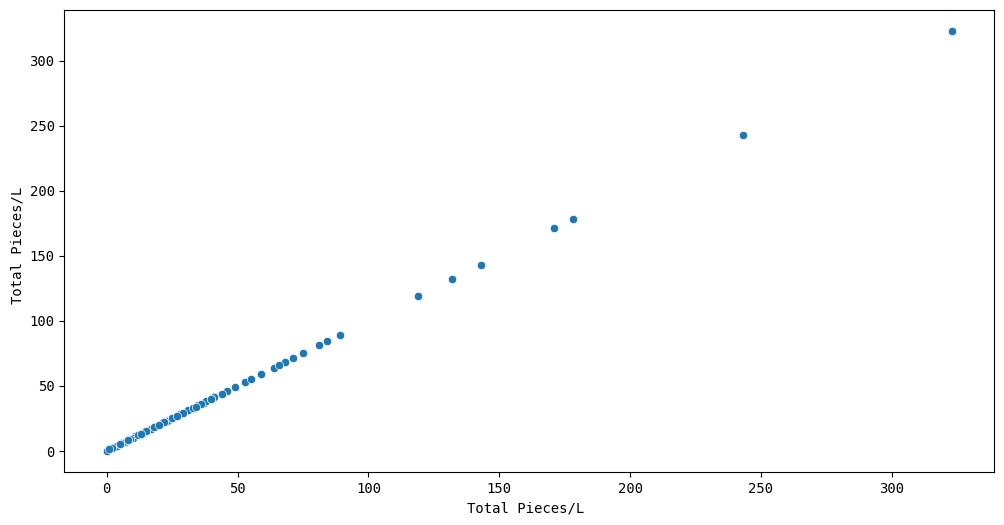

In [ ]:
# Select the first 417 elements from y_test
y_pred = y_test[:417]

# Create the scatter plot
plt.figure(figsize=(12, 6))
ax = sns.scatterplot(x=y_pred, y=y_test)

Modelo para erro máximo.

In [ ]:
# Erros para modelo máximo:

MSE = mean_squared_error(y_test, y_previsto)
RMSE = mean_squared_error(y_test, y_previsto, squared=False)

In [ ]:
print(f'MSE = {MSE:.2f}')
print(f'RMSE = {RMSE:.2f}')

MSE = 758.58
RMSE = 27.54
